<a href="https://colab.research.google.com/github/hanshunyi0-cyber/mlp-s10-case-study/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s10-penguins-train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1 — Train and save a penguin classifier

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/racousin/data_science_practice/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s10-penguins-train.ipynb)

The first step of the deployment workshop. This notebook trains a model and saves it to **one file**, `model.joblib`. Step 2 loads that file in an API on your laptop.

Run every cell from top to bottom (*Runtime → Run all*).

## 1. The data

The **Palmer penguins**: 344 penguins of three species, measured on three islands of Antarctica between 2007 and 2009 (CC0, [allisonhorst/palmerpenguins](https://github.com/allisonhorst/palmerpenguins)).

In [1]:
import pandas as pd

URL = ("https://raw.githubusercontent.com/allisonhorst/"
       "palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(URL)
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


The model uses the four numeric measurements. Two penguins have none of them: those rows are dropped.

In [2]:
FEATURES = ["bill_length_mm", "bill_depth_mm",
            "flipper_length_mm", "body_mass_g"]
df = df.dropna(subset=FEATURES)
print(len(df), "penguins")
df["species"].value_counts()

342 penguins


,count
species,
Adelie,151
Gentoo,123
Chinstrap,68


In [3]:
df[FEATURES].describe().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


Two measurements already separate the three species well:

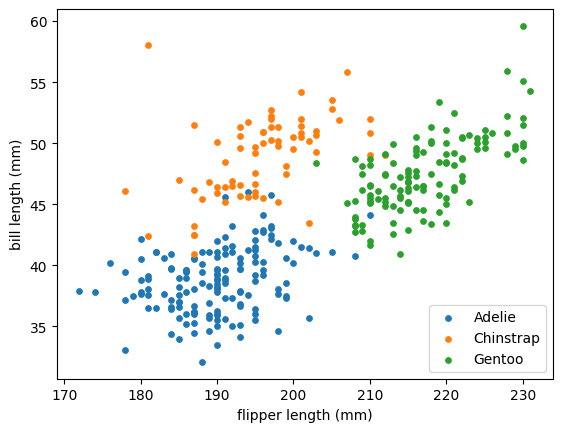

In [4]:
import matplotlib.pyplot as plt

for species, g in df.groupby("species"):
    plt.scatter(g["flipper_length_mm"], g["bill_length_mm"], label=species, s=15)
plt.xlabel("flipper length (mm)"); plt.ylabel("bill length (mm)")
plt.legend(); plt.show()

## 2. Train

A quarter of the penguins is kept aside to test the model. `stratify` keeps the same species mix in both parts.

In [5]:
from sklearn.model_selection import train_test_split

X, y = df[FEATURES], df["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=0)
len(X_train), len(X_test)

(256, 86)

The **baseline** always answers the most frequent species. A model is useful only above it.

In [6]:
print("baseline:", (y_test == y_train.mode()[0]).mean().round(4))

baseline: 0.4419


The model is a **pipeline**: a scaler, then a logistic regression. The scaler is saved inside the model file, so the API can send raw millimetres and grams.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
print("test accuracy:", round(model.score(X_test, y_test), 4))

test accuracy: 0.9884


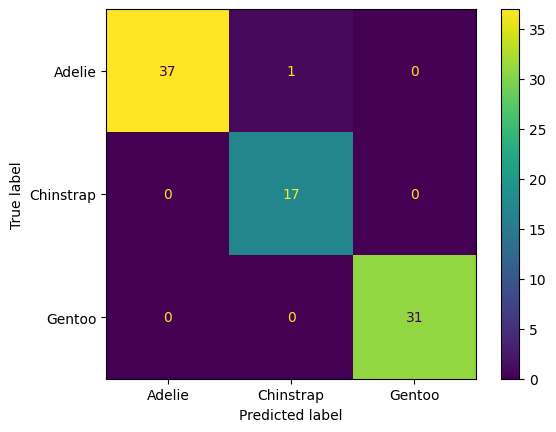

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
plt.show()

## 3. Three penguins to check

The first penguin of each species in the file. The API of Step 2 must give the same three answers.

In [9]:
birds = pd.DataFrame([
    [39.1, 18.7, 181, 3750],   # Adelie
    [46.5, 17.9, 192, 3500],   # Chinstrap
    [46.1, 13.2, 211, 4500],   # Gentoo
], columns=FEATURES)
model.predict(birds)

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

## 4. Save the model

`joblib.dump` writes the fitted pipeline to a file. The file contains the scaler's means, the regression's weights and the class names, but not the code of scikit-learn itself.

In [10]:
import joblib

joblib.dump(model, "model.joblib")

reloaded = joblib.load("model.joblib")
reloaded.predict(birds)

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

## 5. The versions that wrote the file

`model.joblib` is read back correctly by the **same** scikit-learn version. Note these numbers: Step 2 pins them in your project.

In [11]:
import sys, sklearn

print("python      ", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("joblib      ", joblib.__version__)
print("pandas      ", pd.__version__)

python       3.13.15
scikit-learn 1.6.1
joblib       1.6.0
pandas       2.2.3


## 6. Download the file

In Colab, the cell below downloads `model.joblib` to your Downloads folder. Elsewhere, the file is already next to the notebook.

In [12]:
try:
    from google.colab import files
    files.download("model.joblib")
except ImportError:
    print("not in Colab: model.joblib is in", __import__("os").getcwd())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Checkpoint:** `model.joblib` (a few kB) is in your Downloads folder. Next: Step 2, an API that loads it.